# Chapter 5 — The Advanced Proof: Is This Map an Outlier?

So far we have measured maps one at a time. This chapter asks a harder question: **compared to what?**

## The idea, in plain words

Take a state's real map. Now imagine drawing 1,000 *other* legal maps for the same state — same precincts, same voters, same population balance — but drawn with no partisan intent, by a random process. If the real map's efficiency gap sits in the middle of those 1,000 random maps, the map looks ordinary. If it sits far out in the tail, something besides geography is going on.

That random process is called a **Markov chain** (here, the **ReCom** algorithm): at each step it merges two neighboring districts and re-splits them with a random spanning tree, keeping populations balanced. Run it 1,000 times and you get an **ensemble** — a cloud of "what a neutral map could look like."

## The state: Nevada

Nevada has only 4 congressional districts and about 2,100 precincts, so the chain runs in under a minute. Its precinct data comes from the **eveomett-states** project (post-2020 precinct data, built from Redistricting Data Hub / VEST data with the `maup` library, CC BY-NC 4.0). The project's own warning applies here too: this data is **not guaranteed correct in any legal sense and is not for litigation** — it is for learning and research.

## The votes: one baseline for every map

Every map — real and random — is scored with the **same votes: the 2020 presidential vote by precinct** (`PRE20D` / `PRE20R`). That is deliberate: presidential votes are a stable measure of a precinct's partisanship, and using one baseline for all maps makes the comparison apples-to-apples. (It is not the same as scoring with House votes, which is why this chapter's efficiency gap differs from Chapter 2's.)

## Honest caveats, stated before the result

- Our only constraint is **population balance within 10%**. A court-grade analysis would also require compactness and Voting Rights Act compliance. Our random maps are therefore *less* constrained than real legal maps.
- Consecutive chain steps are correlated (each map differs only slightly from the last). A rigorous study would thin the chain or run it much longer. This is a demonstration of the method, not a legal exhibit.


In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q gerrychain pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import os
import statistics
import pandas as pd
import matplotlib.pyplot as plt

DATA = '../data/raw'
NV_JSON = os.path.join(DATA, 'nv.json')
if not os.path.exists(NV_JSON):
    import urllib.request
    url = ('https://raw.githubusercontent.com/eveomett-states/Nevada/'
           'main/nv.json')
    print('Downloading Nevada precinct data...')
    urllib.request.urlretrieve(url, NV_JSON)
print('Nevada data file ready:', NV_JSON, f'({os.path.getsize(NV_JSON) / 1e6:.1f} MB)')

Nevada data file ready: ../data/raw/nv.json (2.8 MB)


In [3]:
from gerrychain import Graph, Partition, MarkovChain, updaters

graph = Graph.from_json(NV_JSON)
print('Precincts (nodes):', len(graph.nodes))

initial = Partition(graph, assignment='CD', updaters={
    'population': updaters.Tally('TOTPOP', alias='population'),
})
print('Districts in the real map:', sorted(initial.parts.keys()))
print('District populations:', {k: round(v) for k, v in initial['population'].items()})

Precincts (nodes): 2094
Districts in the real map: [1, 2, 3, 4]
District populations: {2: 777286, 4: 782963, 3: 773493, 1: 770872}


## The efficiency gap, reused

Same formula as Chapter 1 and 2: wasted votes = loser's votes + winner's surplus above half; efficiency gap = (wasted Republican − wasted Democrat) ÷ total votes. **Positive favors Democrats, negative favors Republicans.** The only difference: here the votes are 2020 presidential votes by precinct, summed within each district of whatever map we are scoring.


In [4]:
def efficiency_gap(partition):
    """Efficiency gap of one map, scored with 2020 presidential votes."""
    wasted_d = wasted_r = total = 0.0
    for nodes in partition.parts.values():
        d = sum(graph.node_data(n)['PRE20D'] for n in nodes)
        r = sum(graph.node_data(n)['PRE20R'] for n in nodes)
        tot = d + r
        total += tot
        if d > r:
            wasted_d += d - tot / 2
            wasted_r += r
        else:
            wasted_r += r - tot / 2
            wasted_d += d
    return (wasted_r - wasted_d) / total


real_eg = efficiency_gap(initial)
print(f'Real Nevada map, efficiency gap (2020 presidential votes): {real_eg * 100:.1f}%')
print('Positive = favors Democrats.')

Real Nevada map, efficiency gap (2020 presidential votes): 19.1%
Positive = favors Democrats.


## The ensemble: 1,000 random maps

This cell takes about 30 seconds. Each step merges two neighboring districts and re-splits them at random (ReCom), keeping every district within 10% of the ideal population. We record the efficiency gap of every map.


In [5]:
from functools import partial
from gerrychain.proposals import recom
from gerrychain.constraints import within_percent_of_ideal_population

ideal_pop = sum(initial['population'].values()) / len(initial.parts)
proposal = partial(recom, pop_col='TOTPOP', pop_target=ideal_pop, epsilon=0.10)


def always_accept(partition, *, rng=None):
    return True


chain = MarkovChain(
    proposal=proposal,
    constraints=[within_percent_of_ideal_population(initial, 0.10)],
    accept=always_accept,
    initial_partition=initial,
    total_steps=1000,
)

ensemble_egs = []
for step, part in enumerate(chain):
    ensemble_egs.append(efficiency_gap(part))
    if (step + 1) % 250 == 0:
        print(f'... {step + 1} maps drawn')

eg_df = pd.DataFrame({'efficiency_gap': ensemble_egs})
eg_df.to_csv('../data/processed/nevada_ensemble_eg.csv', index=False)
print(f'Ensemble complete: {len(eg_df)} maps')
print(f"Mean efficiency gap: {eg_df['efficiency_gap'].mean() * 100:.1f}%")
print(f"Standard deviation: {eg_df['efficiency_gap'].std() * 100:.1f} points")
print(f"Range: {eg_df['efficiency_gap'].min() * 100:.1f}% to {eg_df['efficiency_gap'].max() * 100:.1f}%")
pct = (eg_df['efficiency_gap'] >= real_eg).mean() * 100
print(f'Share of random maps at least as Democratic-leaning as the real map: {pct:.1f}%')
print('Saved to data/processed/nevada_ensemble_eg.csv')

/tmp/ipykernel_18162/1682829662.py:13: DeprecationWarning: MarkovChain.__init__(..., proposal=...) is deprecated; use proposal_fn=... instead. The legacy name will be removed in GerryChain 2.0.
  chain = MarkovChain(
/tmp/ipykernel_18162/1682829662.py:13: DeprecationWarning: MarkovChain.__init__(..., accept=...) is deprecated; use acceptance_fn=... instead. The legacy name will be removed in GerryChain 2.0.
  chain = MarkovChain(


... 250 maps drawn


... 500 maps drawn


... 750 maps drawn


... 1000 maps drawn
Ensemble complete: 1000 maps
Mean efficiency gap: 7.3%
Standard deviation: 13.7 points
Range: -36.1% to 21.4%
Share of random maps at least as Democratic-leaning as the real map: 14.9%
Saved to data/processed/nevada_ensemble_eg.csv


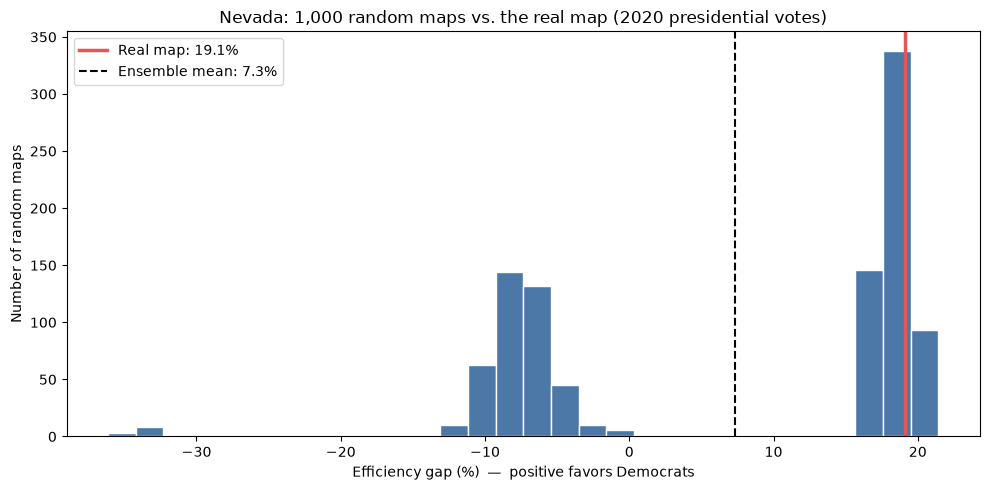

Chart saved to charts/phase5_nevada_ensemble.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(eg_df['efficiency_gap'] * 100, bins=30, color='#4c78a8', edgecolor='white')
ax.axvline(real_eg * 100, color='#e45756', linewidth=2.5,
           label=f'Real map: {real_eg * 100:.1f}%')
ax.axvline(eg_df['efficiency_gap'].mean() * 100, color='black', linewidth=1.5,
           linestyle='--', label=f"Ensemble mean: {eg_df['efficiency_gap'].mean() * 100:.1f}%")
ax.set_xlabel('Efficiency gap (%)  —  positive favors Democrats')
ax.set_ylabel('Number of random maps')
ax.set_title('Nevada: 1,000 random maps vs. the real map (2020 presidential votes)')
ax.legend()
plt.tight_layout()
plt.savefig('../charts/phase5_nevada_ensemble.png', dpi=150)
plt.show()
print('Chart saved to charts/phase5_nevada_ensemble.png')

## How to read this chart — and what it does NOT prove

- The **blue histogram** is the ensemble: what efficiency gaps look like when maps are drawn with no partisan intent (population balance only).
- The **red line** is the real map. The **dashed line** is the ensemble average.
- The real map leans Democratic, and it sits in the upper part of the distribution — but it is **not** beyond it: roughly one in seven random maps leans as far or further in the same direction. That is a *lean*, not a smoking gun.
- Notice also that the ensemble average itself leans Democratic. Why? Geography: Nevada's Democrats are concentrated in Las Vegas, and random maps of a 50–50 state with one big blue metro often waste more Republican votes by accident. **Geography alone can tilt a map.** That is exactly why ensembles exist: they separate "the map is weird" from "the state is shaped that way."

A court-grade version of this test would add compactness and Voting Rights Act constraints, run far more steps, and thin the chain. The method you just ran is the real method — only the scale is a demo.

## Checkpoint — the whole project, in one paragraph

You started with 25 voters and two maps. You measured a real state's map three ways. You drew maps across three elections. You tested a viral claim against 24 elections and found it needed a qualifier — then found the real break in the seats–votes gap after 2010. And now you ran the statistical test professionals use, and learned to read it with restraint. That is a portfolio: a story, told with data, that a recruiter can follow from the first chart to the last.
